- This is solve the trimming problem. In the trimming, past messages are being deleted once the context window gets overflowed. 
- Summarization helps to solve this issue. It summarizes past messages, so that LLM does not lose information entirely. 

![summarization](../images/summarizatoin.png)


In summarization method, we produce summary of the old messages by using an LLM, and then combined the summary with the recent message then send it to the current LLM to generate the answer.

In [23]:
from langgraph.graph import MessagesState
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage, RemoveMessage # it is used to deleted messages parmanently.
from langgraph.graph import StateGraph, START
from langgraph.checkpoint.memory import InMemorySaver

In [24]:
load_dotenv()
model = ChatOpenAI(model = "gpt-4o")

In [25]:
def chat(state: MessagesState):
    response = model.invoke(state["messages"])
    return {"messages": [response]}

def delete_old_messages(state: MessagesState):
    msgs = state["messages"]

    # if more that 10 messages, delete the earliest 6
    if len(msgs)>10:
        to_remove  = msgs[:6]
        return {"messages": [RemoveMessage(id= m.id) for m in to_remove]}
    return {}

In [26]:
builder = StateGraph(MessagesState)
builder.add_node("chat", chat)
builder.add_node("cleanup", delete_old_messages)

In [27]:
builder.add_edge(START, "chat")
builder.add_edge("chat","cleanup")
builder.add_edge("cleanup", "__end__")


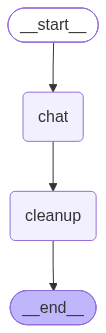

In [28]:
graph = builder.compile(checkpointer=InMemorySaver())
graph

In [29]:
config = {"configurable":{"thread_id":"t1"}}

In [32]:
graph.invoke({"messages":[{"role":"user", "content":"Hi, I am Bani"}]}, config)
graph.invoke({"messages":[{"role":"user", "content":"What is machine learning?"}]}, config)
graph.invoke({"messages":[{"role":"user", "content":"What is SUN?"}]}, config)
graph.invoke({"messages":[{"role":"user", "content":"What is the meaning of Red bull?"}]}, config)
graph.invoke({"messages":[{"role":"user", "content":"What is bottleneck?"}]}, config)
graph.invoke({"messages":[{"role":"user", "content":"Hi, how are you?"}]}, config)
graph.invoke({"messages":[{"role":"user", "content":"Hi,what is my name?"}]}, config)

{'messages': [HumanMessage(content='What is bottleneck?', additional_kwargs={}, response_metadata={}, id='5c458b6e-3ce4-4334-b3bb-c804f8421595'),
  AIMessage(content='In general terms, a bottleneck refers to a point of congestion or obstruction that limits the efficiency, performance, or capacity of a system or process. The term is derived from the narrow neck of a bottle, where liquid flow is restricted compared to the wider body of the bottle. In various contexts, bottlenecks can manifest in the following ways:\n\n1. **Production and Operations**: In manufacturing or any production process, a bottleneck is a stage where the production capacity is limited, causing delays and reducing overall output. This can occur due to machinery limitations, labor shortages, or inefficiencies in the workflow.\n\n2. **Computing and Technology**: In computer systems, a bottleneck occurs when the capacity of an application or system component is limited by a particular resource, typically affecting ove

In [33]:
snap = graph.get_state(config)
print("Stored messages after cleaned up", len(snap.values["messages"]))

Stored messages after cleaned up 6


# -----------------------------------------------------------------

- so far we performed messages deletion. 
- Now, we will proceed to the summarization. ---
- As the number of messages is greater than 6, keeping the recent 2 intact and we summarize 4 older messages and add then with the recent 2. 


In [37]:
from langgraph.graph import MessagesState
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage, RemoveMessage
from langgraph.graph import StateGraph, START
from langgraph.checkpoint.memory import InMemorySaver

In [38]:
load_dotenv()

model = ChatOpenAI(model = 'gpt-4o')

In [39]:
class ChatState(MessagesState):
    summary: str

In [40]:
def summarize_conversation(state: ChatState):
    """here two activities are being performed - deletion and summerization"""
    existing_summary = state["summary"]

    # Build summarization prompt
    if existing_summary:
        prompt = (
            f"Existing summary:\n{existing_summary}\n\n"
            "Extend the summary using the new conversation above."
        )
    else:
        prompt = "Summarize the conversation above."

    messages_for_summary = state["messages"] + [
        HumanMessage(content=prompt)
    ]

    response = model.invoke(messages_for_summary)

    # Keep only last 2 messages verbatim
    messages_to_delete = state["messages"][:-2]

    return {
        "summary": response.content,
        "messages": [RemoveMessage(id=m.id) for m in messages_to_delete],
    }

In [41]:
def chat_node(state: ChatState):
    messages = []

    if state["summary"]:
        messages.append({
            "role": "system",
            "content": f"Conversation summary:\n{state['summary']}"
        })

    messages.extend(state["messages"])

    print(messages)

    response = model.invoke(messages)
    return {"messages": [response]}

In [42]:

def should_summarize(state: ChatState):
    return len(state["messages"]) > 6

In [43]:
builder = StateGraph(ChatState)

builder.add_node("chat", chat_node)
builder.add_node("summarize", summarize_conversation)

builder.add_edge(START, "chat")

builder.add_conditional_edges(
    "chat",
    should_summarize,
    {
        True: "summarize",
        False: "__end__",
    }
)

builder.add_edge("summarize", "__end__")

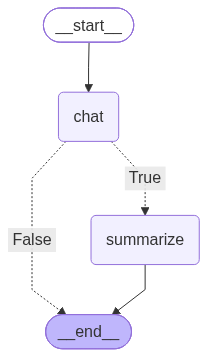

In [44]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)
graph

In [45]:

config = {"configurable": {"thread_id": "t1"}}

def run_turn(text: str):
    out = graph.invoke({"messages": [HumanMessage(content=text)], "summary": ""}, config=config)
    return out

In [46]:
# gives the current version of the state
def show_state():
    snap = graph.get_state(config)
    vals = snap.values
    print("\n--- STATE ---")
    print("summary:", vals.get("summary", ""))
    print("num_messages:", len(vals.get("messages", [])))
    print("messages:")
    for m in vals.get("messages", []):
        print("-", type(m).__name__, ":", m.content[:80])

In [47]:

run_turn('Quantum Physics')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='a01b31ed-9eb4-4900-a474-e5681914d472')]

--- STATE ---
summary: 
num_messages: 2
messages:
- HumanMessage : Quantum Physics
- AIMessage : Quantum physics, also known as quantum mechanics, is a fundamental theory in phy


In [48]:

run_turn('What are some of Einstien"s fampus work')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='a01b31ed-9eb4-4900-a474-e5681914d472'), AIMessage(content="Quantum physics, also known as quantum mechanics, is a fundamental theory in physics that provides a description of the physical properties of nature at the smallest scales, such as atoms and subatomic particles. Here are some key concepts and principles in quantum physics:\n\n1. **Wave-Particle Duality**: Particles such as electrons exhibit both wave-like and particle-like properties. This means they can show interference patterns like waves and exhibit particle properties like discrete interactions.\n\n2. **Quantum States and Superposition**: Quantum systems can exist in multiple states simultaneously until they are observed or measured. This is known as superposition. When measured, the system 'collapses' into one of the possible states.\n\n3. **Quantization**: Certain properties, such as energy, can only take on discrete values. This qu

In [49]:
run_turn('Explain special theory of relativity')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='a01b31ed-9eb4-4900-a474-e5681914d472'), AIMessage(content="Quantum physics, also known as quantum mechanics, is a fundamental theory in physics that provides a description of the physical properties of nature at the smallest scales, such as atoms and subatomic particles. Here are some key concepts and principles in quantum physics:\n\n1. **Wave-Particle Duality**: Particles such as electrons exhibit both wave-like and particle-like properties. This means they can show interference patterns like waves and exhibit particle properties like discrete interactions.\n\n2. **Quantum States and Superposition**: Quantum systems can exist in multiple states simultaneously until they are observed or measured. This is known as superposition. When measured, the system 'collapses' into one of the possible states.\n\n3. **Quantization**: Certain properties, such as energy, can only take on discrete values. This qu

In [50]:
run_turn('Explain special gravity')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='a01b31ed-9eb4-4900-a474-e5681914d472'), AIMessage(content="Quantum physics, also known as quantum mechanics, is a fundamental theory in physics that provides a description of the physical properties of nature at the smallest scales, such as atoms and subatomic particles. Here are some key concepts and principles in quantum physics:\n\n1. **Wave-Particle Duality**: Particles such as electrons exhibit both wave-like and particle-like properties. This means they can show interference patterns like waves and exhibit particle properties like discrete interactions.\n\n2. **Quantum States and Superposition**: Quantum systems can exist in multiple states simultaneously until they are observed or measured. This is known as superposition. When measured, the system 'collapses' into one of the possible states.\n\n3. **Quantization**: Certain properties, such as energy, can only take on discrete values. This qu